## La formule

$G = M [(1 + r)^n - 1]$

In [13]:
M = 1_000  # mise initiale (EUR)
r = 0.10   # rendement annuel
n = 35     # nombre d'années

G = M * ((1 + r) ** n - 1)

print(f"Montant final : {M + G:,.2f} €".replace(",", " "))
print(f"Gain          : {G:,.2f} €".replace(",", " "))

Montant final : 28 102.44 €
Gain          : 27 102.44 €


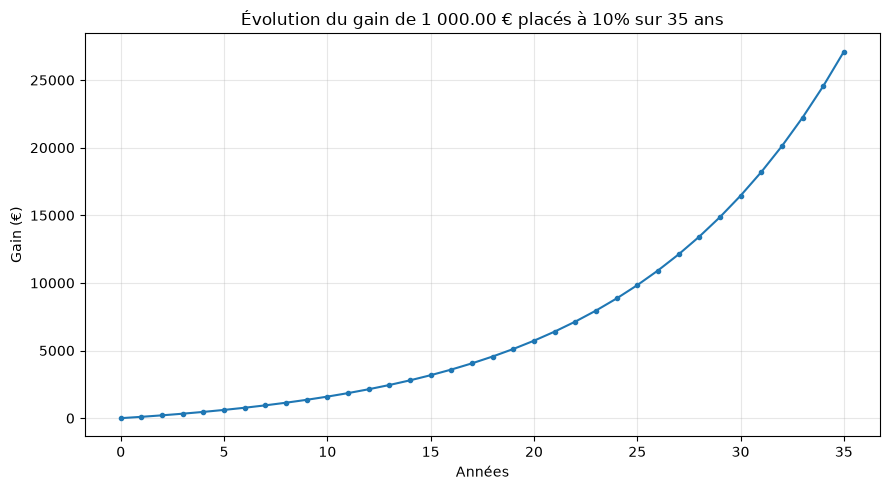

In [14]:
import matplotlib.pyplot as plt

M = 1_000  # mise initiale (€)
r = 0.10   # rendement annuel
N = 35   # duree max (annees)

annees = list(range(N + 1))
gains = [M * ((1 + r) ** n - 1) for n in annees]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(annees, gains, marker='o', markersize=3)
ax.set_xlabel("Années")
ax.set_ylabel("Gain (€)")
ax.set_title(f"Évolution du gain de {M:,.2f} € placés à {r:.0%} sur {N} ans".replace(",", " "))
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Qu'est-ce qui se passe si le rendement varie?

$
\frac{\partial G}{\partial r} = M \, n \, (1+r)^{n-1}
$



In [15]:
M = 1_000  # montant initiale (€)
n = 35     # nombre d'années

def gain(r):
    return M * ((1 + r) ** n - 1)

def derivee(r):
    return M * n * (1 + r) ** (n - 1)

def fmt(x):
    return f"{x:,.0f} €".replace(",", " ")

print(f"{'r':>5} | {'Gain G':>10} | {'dG/dr':>12} | {'Pente / point':>13} | {'G(r+1%) - G(r)':>14}")
print("-" * 68)
for pct in range(1, 11):
    r = pct / 100
    print(f"{r:>5.0%} | {fmt(gain(r)):>10} | {fmt(derivee(r)):>12} | "
          f"{fmt(derivee(r) / 100):>13} | {fmt(gain(r + 0.01) - gain(r)):>14}")

    r |     Gain G |        dG/dr | Pente / point | G(r+1%) - G(r)
--------------------------------------------------------------------
   1% |      417 € |     49 090 € |         491 € |          583 €
   2% |    1 000 € |     68 624 € |         686 € |          814 €
   3% |    1 814 € |     95 617 € |         956 € |        1 132 €
   4% |    2 946 € |    132 801 € |       1 328 € |        1 570 €
   5% |    4 516 € |    183 867 € |       1 839 € |        2 170 €
   6% |    6 686 € |    253 786 € |       2 538 € |        2 990 €
   7% |    9 677 € |    349 234 € |       3 492 € |        4 109 €
   8% |   13 785 € |    479 155 € |       4 792 € |        5 629 €
   9% |   19 414 € |    655 494 € |       6 555 € |        7 688 €
  10% |   27 102 € |    894 168 € |       8 942 € |       10 472 €


### La tangente sous-estime une courbe qui accélère


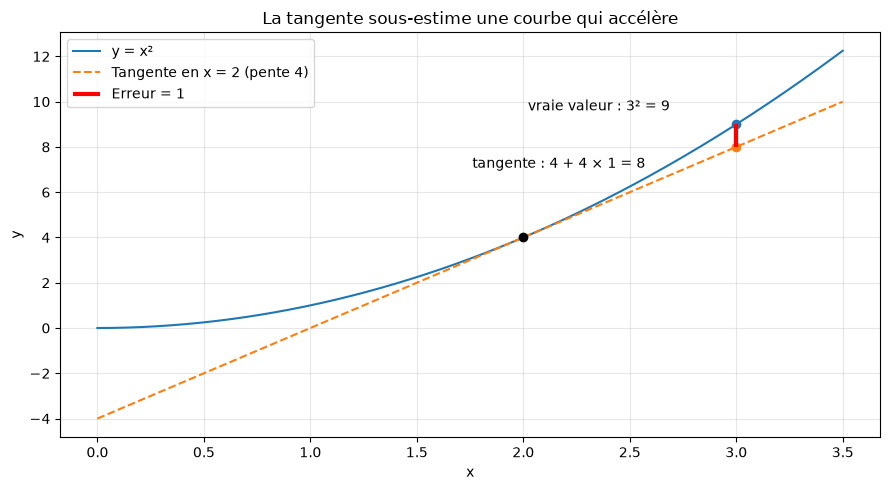

f(3) = 9, tangente en x = 3 : 8, erreur = 1


In [16]:
import matplotlib.pyplot as plt

x0 = 2   # point où l'on trace la tangente
x1 = 3   # point où l'on utilise la tangente pour estimer f

def f(x):
    return x ** 2

pente = 2 * x0  # f'(x) = 2x

xs = [i / 100 for i in range(0, 351)]  # 0 à 3.5
courbe = [f(x) for x in xs]
tangente = [f(x0) + pente * (x - x0) for x in xs]

vrai = f(x1)                               # vraie valeur
estim = f(x0) + pente * (x1 - x0)          # estimation par la tangente
erreur = vrai - estim

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(xs, courbe, label="y = x²")
ax.plot(xs, tangente, linestyle="--", label=f"Tangente en x = {x0} (pente {pente})")
ax.plot([x0], [f(x0)], marker="o", color="black")
ax.plot([x1], [vrai], marker="o", color="tab:blue")
ax.plot([x1], [estim], marker="o", color="tab:orange")

# Erreur : écart vertical entre la courbe et la tangente en x1
ax.vlines(x1, estim, vrai, color="red", linewidth=3, label=f"Erreur = {erreur:g}")
ax.annotate(f"vraie valeur : {x1}² = {vrai:g}", (x1, vrai), xytext=(-150, 10), textcoords="offset points")
ax.annotate(f"tangente : {f(x0):g} + {pente} × {x1 - x0} = {estim:g}", (x1, estim),
            xytext=(-190, -15), textcoords="offset points")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("La tangente sous-estime une courbe qui accélère")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"f({x1}) = {vrai:g}, tangente en x = {x1} : {estim:g}, erreur = {erreur:g}")

### Illustration du tableau précédent

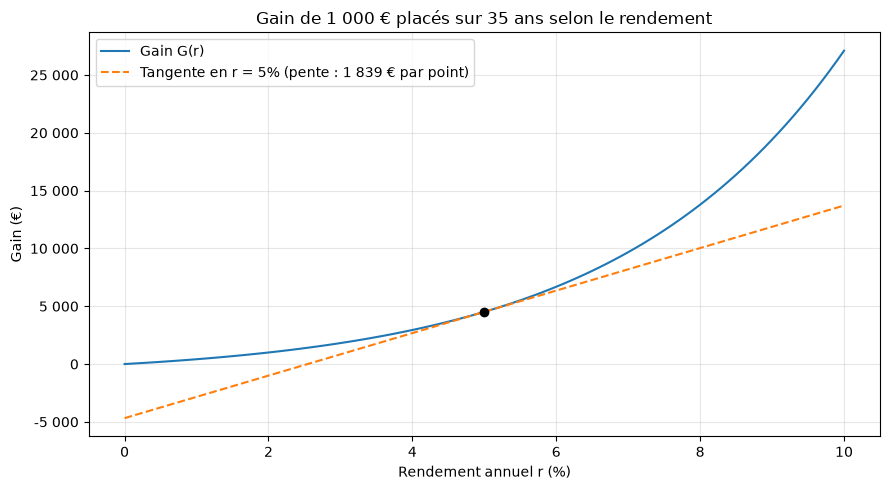

In [17]:
import matplotlib.pyplot as plt

M = 1_000  # mise initiale (€)
n = 35     # nombre d'années
r0 = 0.05  # point où l'on trace la tangente

rs = [i / 1000 for i in range(0, 101)]  # 0 % à 10 %
gains = [M * ((1 + r) ** n - 1) for r in rs]

G0 = M * ((1 + r0) ** n - 1)
pente = M * n * (1 + r0) ** (n - 1)
tangente = [G0 + pente * (r - r0) for r in rs]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([r * 100 for r in rs], gains, label="Gain G(r)")
ax.plot([r * 100 for r in rs], tangente, linestyle="--",
        label=f"Tangente en r = {r0:.0%} (pente : {pente / 100:,.0f} € par point)".replace(",", " "))
ax.plot([r0 * 100], [G0], marker="o", color="black")
ax.set_xlabel("Rendement annuel r (%)")
ax.set_ylabel("Gain (€)")
ax.set_title(f"Gain de {M:,.0f} € placés sur {n} ans selon le rendement".replace(",", " "))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Qu'est-ce qui se passe si la durée varie?

$
\frac{\partial G}{\partial n} = M \, (1+r)^n \ln(1+r)
$

In [18]:
import math

M = 1_000  # mise initiale (€)
r = 0.05   # rendement annuel

def gain(n):
    return M * ((1 + r) ** n - 1)

def derivee(n):
    return M * (1 + r) ** n * math.log(1 + r)

def fmt(x):
    return f"{x:,.0f} €".replace(",", " ")

print(f"{'n':>4} | {'Gain G':>10} | {'dG/dn':>10} | {'G(n+1) - G(n)':>13}")
print("-" * 47)
for n in range(0, 71, 5):
    print(f"{n:>4} | {fmt(gain(n)):>10} | {fmt(derivee(n)):>10} | {fmt(gain(n + 1) - gain(n)):>13}")

   n |     Gain G |      dG/dn | G(n+1) - G(n)
-----------------------------------------------
   0 |        0 € |       49 € |          50 €
   5 |      276 € |       62 € |          64 €
  10 |      629 € |       79 € |          81 €
  15 |    1 079 € |      101 € |         104 €
  20 |    1 653 € |      129 € |         133 €
  25 |    2 386 € |      165 € |         169 €
  30 |    3 322 € |      211 € |         216 €
  35 |    4 516 € |      269 € |         276 €
  40 |    6 040 € |      343 € |         352 €
  45 |    7 985 € |      438 € |         449 €
  50 |   10 467 € |      559 € |         573 €
  55 |   13 636 € |      714 € |         732 €
  60 |   17 679 € |      911 € |         934 €
  65 |   22 840 € |    1 163 € |       1 192 €
  70 |   29 426 € |    1 485 € |       1 521 €


### Le gain en fonction de la durée

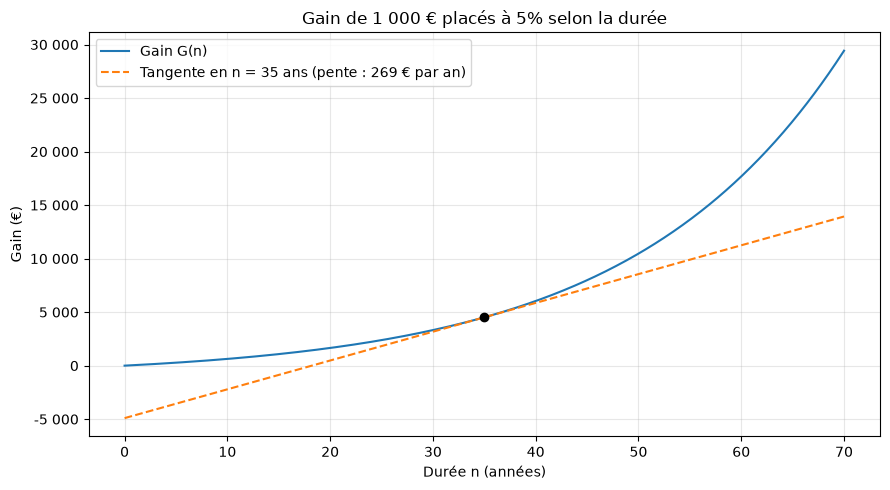

In [19]:
import math
import matplotlib.pyplot as plt

M = 1_000  # mise initiale (€)
r = 0.05   # rendement annuel
N = 70     # durée max (années)
n0 = 35    # point où l'on trace la tangente

ns = [i / 10 for i in range(0, 10 * N + 1)]  # 0 à 70 ans
gains = [M * ((1 + r) ** n - 1) for n in ns]

G0 = M * ((1 + r) ** n0 - 1)
pente = M * (1 + r) ** n0 * math.log(1 + r)
tangente = [G0 + pente * (n - n0) for n in ns]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns, gains, label="Gain G(n)")
ax.plot(ns, tangente, linestyle="--",
        label=f"Tangente en n = {n0} ans (pente : {pente:,.0f} € par an)".replace(",", " "))
ax.plot([n0], [G0], marker="o", color="black")
ax.set_xlabel("Durée n (années)")
ax.set_ylabel("Gain (€)")
ax.set_title(f"Gain de {M:,.0f} € placés à {r:.0%} selon la durée".replace(",", " "))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Effet relatif, élasticité

   n |    E_r |    E_n | E_n / E_r
-----------------------------------
   1 |  1.000 |  1.025 |    1.0246
   5 |  1.100 |  1.127 |    1.0246
  10 |  1.233 |  1.264 |    1.0246
  15 |  1.376 |  1.410 |    1.0246
  20 |  1.528 |  1.566 |    1.0246
  25 |  1.689 |  1.731 |    1.0246
  30 |  1.859 |  1.904 |    1.0246
  35 |  2.036 |  2.086 |    1.0246
  40 |  2.220 |  2.275 |    1.0246
  45 |  2.411 |  2.471 |    1.0246
  50 |  2.608 |  2.673 |    1.0246


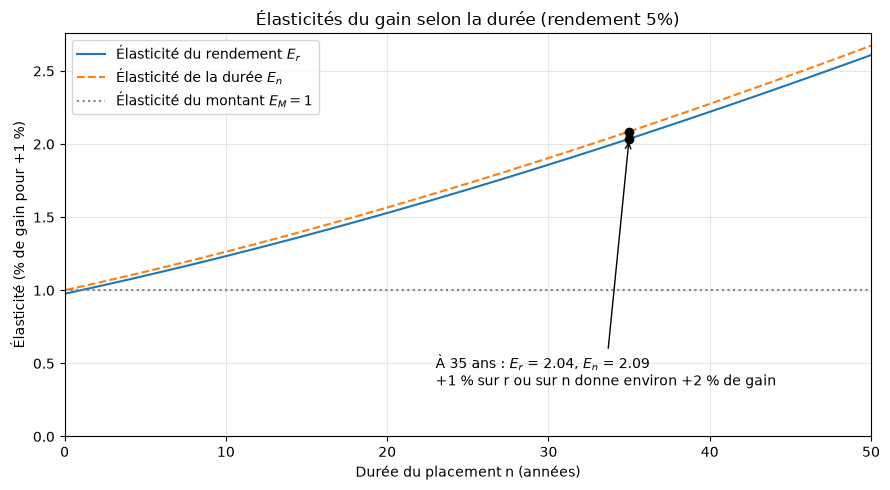

In [20]:
import math
import matplotlib.pyplot as plt

r = 0.05   # rendement annuel
N = 50     # durée max (années)
n0 = 35    # durée de référence

def E_r(n):
    return n * r * (1 + r) ** (n - 1) / ((1 + r) ** n - 1)

def E_n(n):
    return n * (1 + r) ** n * math.log(1 + r) / ((1 + r) ** n - 1)

print(f"{'n':>4} | {'E_r':>6} | {'E_n':>6} | {'E_n / E_r':>9}")
print("-" * 35)
for n in [1] + list(range(5, N + 1, 5)):
    print(f"{n:>4} | {E_r(n):>6.3f} | {E_n(n):>6.3f} | {E_n(n) / E_r(n):>9.4f}")

ns = [i / 10 for i in range(1, 10 * N + 1)]  # 0.1 à 50 ans (n = 0 interdit : division par 0)
er = [E_r(n) for n in ns]
en = [E_n(n) for n in ns]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns, er, label="Élasticité du rendement $E_r$")
ax.plot(ns, en, linestyle="--", label="Élasticité de la durée $E_n$")
ax.axhline(1, color="gray", linestyle=":", label="Élasticité du montant $E_M = 1$")

# Point de référence : 35 ans
ax.plot([n0, n0], [E_r(n0), E_n(n0)], marker="o", linestyle="none", color="black")
ax.annotate(f"À {n0} ans : $E_r$ = {E_r(n0):.2f}, $E_n$ = {E_n(n0):.2f}\n"
            f"+1 % sur r ou sur n donne environ +{E_r(n0):.0f} % de gain",
            (n0, E_r(n0)), xytext=(n0 - 12, 0.35),
            arrowprops=dict(arrowstyle="->"))

ax.set_xlim(0, N)
ax.set_ylim(0, None)
ax.set_xlabel("Durée du placement n (années)")
ax.set_ylabel("Élasticité (% de gain pour +1 %)")
ax.set_title(f"Élasticités du gain selon la durée (rendement {r:.0%})")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Les frais composés

Gain sans frais (5.0%)          : 4 516 €
Gain avec frais (4.5% net)      : 3 667 €
Coût des frais au bout de 35 ans : 849 € (19% du gain)


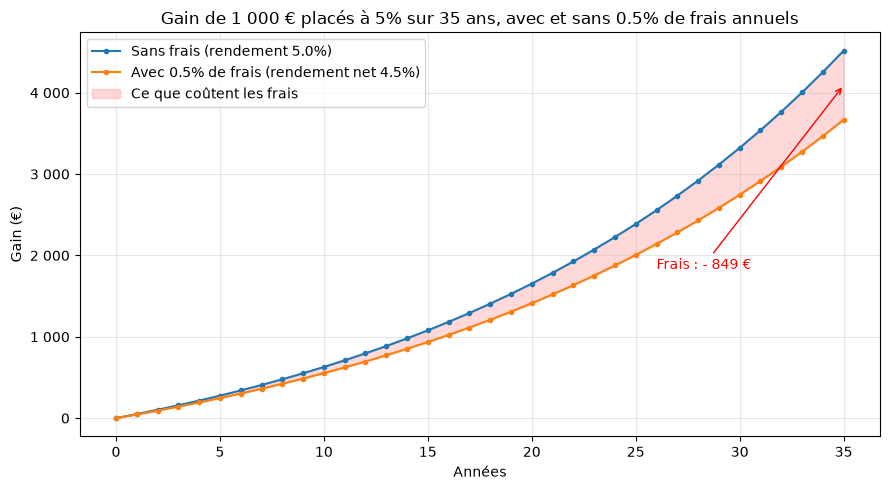

In [21]:
import matplotlib.pyplot as plt

M = 1_000      # mise initiale (€)
r = 0.05       # rendement annuel brut
frais = 0.005  # frais annuels (0.5 %)
N = 35         # durée (années)

def gain(taux, n):
    return M * ((1 + taux) ** n - 1)

def fmt(x):
    return f"{x:,.0f} €".replace(",", " ")

annees = list(range(N + 1))
sans_frais = [gain(r, n) for n in annees]
avec_frais = [gain(r - frais, n) for n in annees]  # les frais se soustraient au rendement

G_sans = sans_frais[-1]
G_avec = avec_frais[-1]
perte = G_sans - G_avec

print(f"Gain sans frais ({r:.1%})          : {fmt(G_sans)}")
print(f"Gain avec frais ({r - frais:.1%} net)      : {fmt(G_avec)}")
print(f"Coût des frais au bout de {N} ans : {fmt(perte)} ({perte / G_sans:.0%} du gain)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(annees, sans_frais, marker="o", markersize=3, label=f"Sans frais (rendement {r:.1%})")
ax.plot(annees, avec_frais, marker="o", markersize=3, label=f"Avec {frais:.1%} de frais (rendement net {r - frais:.1%})")
ax.fill_between(annees, avec_frais, sans_frais, color="red", alpha=0.15, label="Ce que coûtent les frais")
ax.annotate(f"Frais : - {fmt(perte)}", (N, (G_sans + G_avec) / 2), xytext=(N - 9, G_avec * 0.5),
            color="red", arrowprops=dict(arrowstyle="->", color="red"))
ax.set_xlabel("Années")
ax.set_ylabel("Gain (€)")
ax.set_title(f"Gain de {fmt(M)} placés à {r:.0%} sur {N} ans, avec et sans {frais:.1%} de frais annuels")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Le PEA Jeune de Marty

Gain sans frais (10.0%)          : 775 736 €
Gain avec frais (9.8% net)      : 705 197 €
Coût des frais au bout de 52 ans : 70 539 € (9% du gain)


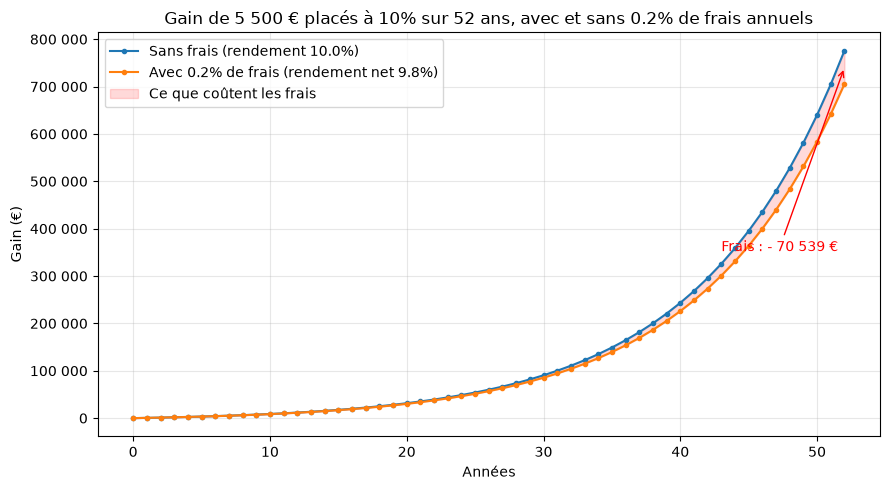

In [22]:
import matplotlib.pyplot as plt

M = 5_500      # mise initiale (€)
r = 0.10       # rendement annuel brut 10%
frais = 0.002  # frais annuels (0.2 %)
N = 52         # durée (années)

def gain(taux, n):
    return M * ((1 + taux) ** n - 1)

def fmt(x):
    return f"{x:,.0f} €".replace(",", " ")

annees = list(range(N + 1))
sans_frais = [gain(r, n) for n in annees]
avec_frais = [gain(r - frais, n) for n in annees]  # les frais se soustraient au rendement

G_sans = sans_frais[-1]
G_avec = avec_frais[-1]
perte = G_sans - G_avec

print(f"Gain sans frais ({r:.1%})          : {fmt(G_sans)}")
print(f"Gain avec frais ({r - frais:.1%} net)      : {fmt(G_avec)}")
print(f"Coût des frais au bout de {N} ans : {fmt(perte)} ({perte / G_sans:.0%} du gain)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(annees, sans_frais, marker="o", markersize=3, label=f"Sans frais (rendement {r:.1%})")
ax.plot(annees, avec_frais, marker="o", markersize=3, label=f"Avec {frais:.1%} de frais (rendement net {r - frais:.1%})")
ax.fill_between(annees, avec_frais, sans_frais, color="red", alpha=0.15, label="Ce que coûtent les frais")
ax.annotate(f"Frais : - {fmt(perte)}", (N, (G_sans + G_avec) / 2), xytext=(N - 9, G_avec * 0.5),
            color="red", arrowprops=dict(arrowstyle="->", color="red"))
ax.set_xlabel("Années")
ax.set_ylabel("Gain (€)")
ax.set_title(f"Gain de {fmt(M)} placés à {r:.0%} sur {N} ans, avec et sans {frais:.1%} de frais annuels")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Le complément de retraite de Marty

* 18 à 23 ans : les 5 500 € travaillent seuls
* 23 à 70 ans : DCA mensuel de 1 % du salaire, salaire augmenté chaque année
* 70 à 100 ans : retrait de 4 % par an, prélèvements de 18.6 % sur la part de gain de chaque retrait
* Résultats en euros courants et en euros d'aujourd'hui (inflation)

Premier DCA mensuel (à 23 ans)          : 25 €
Dernier DCA mensuel (à 69 ans)          : 78 €
Total versé (5 500 € + DCA)             : 31 800 €
Capital à 70 ans                        : 1 044 437 €  soit 372 970 € d'aujourd'hui
Complément mensuel net à 70 ans         : 2 853 €      soit 999 € d'aujourd'hui
Complément mensuel net à 99 ans         : 13 855 €     soit 2 732 € d'aujourd'hui
Impôts payés sur les retraits           : 571 027 €
Capital restant à 100 ans               : 5 391 162 €  soit 1 062 841 € d'aujourd'hui


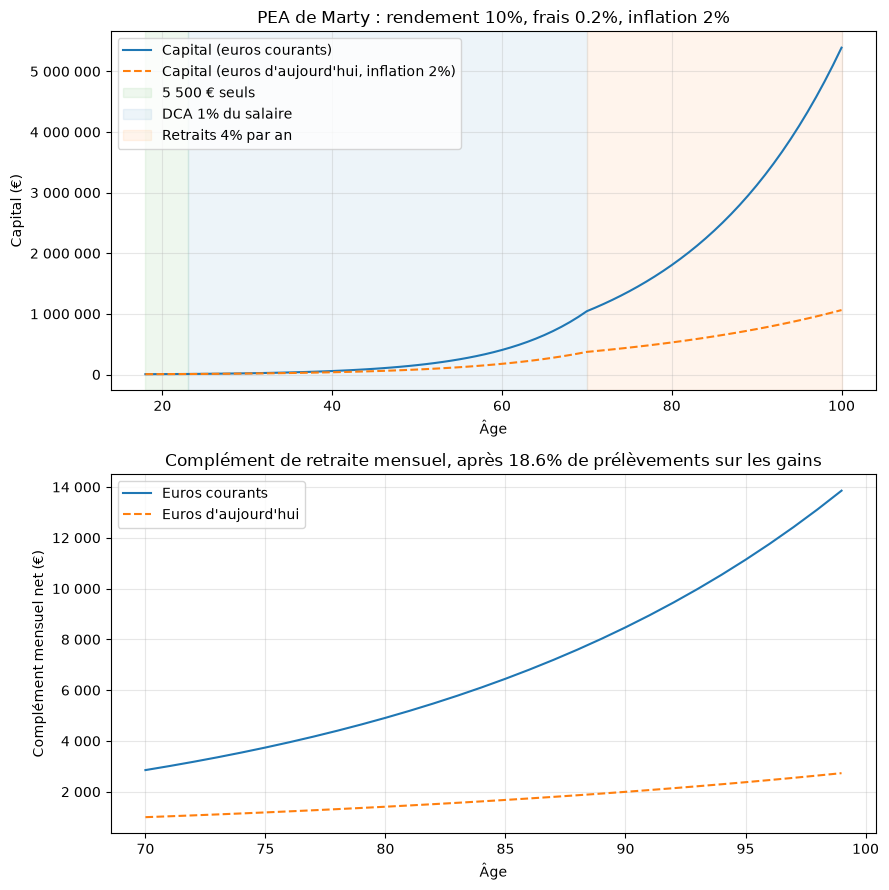

In [23]:
import matplotlib.pyplot as plt

# --- Paramètres ---------------------------------------------------------
M = 5_500               # mise initiale à 18 ans (€)
r = 0.10                # rendement annuel brut
frais = 0.002           # frais annuels (0.2 %)
inflation = 0.02        # inflation annuelle (objectif de la BCE)

salaire_net = 2_500     # salaire net mensuel au premier emploi (€)
hausse_salaire = 0.025  # augmentation annuelle du salaire
part_dca = 0.01         # part du salaire versée chaque mois sur le PEA (DCA)

taux_retrait = 0.04     # retrait annuel (% de l'épargne) à partir de la retraite
fiscalite = 0.186       # prélèvements sur la part de gain de chaque retrait

age_debut = 18          # début du placement (demain)
age_dca = 23            # premier salaire, début du DCA
age_retraite = 70       # fin du DCA, début des retraits
age_fin = 100           # fin de la simulation

r_mois = (1 + r - frais) ** (1 / 12) - 1  # rendement net mensuel équivalent


def fmt(x):
    return f"{x:,.0f} €".replace(",", " ")


# --- Simulation mois par mois -------------------------------------------
capital = M        # valeur du PEA
base = M           # versements encore présents dans le PEA (ce qui n'est pas du gain)
total_verse = M    # cumul de tous les versements
total_impots = 0

ages, capital_nominal, capital_reel = [age_debut], [capital], [capital]
ages_retraite, revenu_nominal, revenu_reel = [], [], []
premier_dca = None
dernier_dca = 0

for annee in range(age_fin - age_debut):
    age = age_debut + annee

    # Versement mensuel : 1 % du salaire de l'année, entre 23 et 70 ans
    if age_dca <= age < age_retraite:
        dca = part_dca * salaire_net * (1 + hausse_salaire) ** (age - age_dca)
        if premier_dca is None:
            premier_dca = dca
        dernier_dca = dca
    else:
        dca = 0

    # Retrait mensuel : 4 % par an de l'épargne au 1er janvier, découpé en 12
    retrait = taux_retrait * capital / 12 if age >= age_retraite else 0

    net_annee = 0
    for mois in range(12):
        capital *= 1 + r_mois
        capital += dca
        base += dca
        total_verse += dca
        if retrait:
            part_versement = base / capital          # part du retrait qui est du capital versé
            impot = retrait * (1 - part_versement) * fiscalite
            base -= retrait * part_versement
            capital -= retrait
            total_impots += impot
            net_annee += retrait - impot

    deflateur = (1 + inflation) ** (annee + 1)  # pour exprimer en euros d'aujourd'hui
    ages.append(age + 1)
    capital_nominal.append(capital)
    capital_reel.append(capital / deflateur)
    if retrait:
        ages_retraite.append(age)
        revenu_nominal.append(net_annee / 12)
        revenu_reel.append(net_annee / 12 / deflateur)

# --- Résultats -----------------------------------------------------------
i70 = age_retraite - age_debut
print(f"Premier DCA mensuel (à {age_dca} ans)          : {fmt(premier_dca)}")
print(f"Dernier DCA mensuel (à {age_retraite - 1} ans)          : {fmt(dernier_dca)}")
print(f"Total versé ({fmt(M)} + DCA)             : {fmt(total_verse)}")
print(f"Capital à {age_retraite} ans                        : {fmt(capital_nominal[i70])}"
      f"  soit {fmt(capital_reel[i70])} d'aujourd'hui")
print(f"Complément mensuel net à {age_retraite} ans         : {fmt(revenu_nominal[0])}"
      f"      soit {fmt(revenu_reel[0])} d'aujourd'hui")
print(f"Complément mensuel net à {age_fin - 1} ans         : {fmt(revenu_nominal[-1])}"
      f"     soit {fmt(revenu_reel[-1])} d'aujourd'hui")
print(f"Impôts payés sur les retraits           : {fmt(total_impots)}")
print(f"Capital restant à {age_fin} ans               : {fmt(capital_nominal[-1])}"
      f"  soit {fmt(capital_reel[-1])} d'aujourd'hui")

# --- Graphiques ----------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9))

ax1.plot(ages, capital_nominal, label="Capital (euros courants)")
ax1.plot(ages, capital_reel, linestyle="--", label=f"Capital (euros d'aujourd'hui, inflation {inflation:.0%})")
ax1.axvspan(age_debut, age_dca, color="tab:green", alpha=0.08, label=f"{fmt(M)} seuls")
ax1.axvspan(age_dca, age_retraite, color="tab:blue", alpha=0.08, label=f"DCA {part_dca:.0%} du salaire")
ax1.axvspan(age_retraite, age_fin, color="tab:orange", alpha=0.08, label=f"Retraits {taux_retrait:.0%} par an")
ax1.set_xlabel("Âge")
ax1.set_ylabel("Capital (€)")
ax1.set_title(f"PEA de Marty : rendement {r:.0%}, frais {frais:.1%}, inflation {inflation:.0%}")
ax1.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

ax2.plot(ages_retraite, revenu_nominal, label="Euros courants")
ax2.plot(ages_retraite, revenu_reel, linestyle="--", label="Euros d'aujourd'hui")
ax2.set_xlabel("Âge")
ax2.set_ylabel("Complément mensuel net (€)")
ax2.set_title(f"Complément de retraite mensuel, après {fiscalite:.1%} de prélèvements sur les gains")
ax2.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left")

fig.tight_layout()
plt.show()